## Generation, Cross-Generation and Reconstruction

In [1]:
import torch
import matplotlib.pyplot as plt
import random
from collections import defaultdict
from torch.utils.data import DataLoader, Dataset
import torchvision
import torchvision.transforms as T

In [2]:
# Initializing the corresponding classes
from Nets import Encoder, Decoder, multiviewVAE
from architecture import mnist_encoder_conv_stack,mnist_decoder_conv_stack, shvn_decoder_conv_stack, shvn_encoder_conv_stack, encoder_linear_stack, decoder_linear_stack

latent_dim = 20

# Initializing encoder
encoder1 = Encoder(
    latent_dim, mnist_encoder_conv_stack(), encoder_linear_stack(latent_dim)
)
encoder2 = Encoder(
    latent_dim, shvn_encoder_conv_stack(), encoder_linear_stack(latent_dim)
)

# Initializing decoder
decoder1 = Decoder(
    mnist_decoder_conv_stack(),
    decoder_linear_stack(latent_dim),
    channels=256,
    height=1,
    width=1,
)
decoder2 = Decoder(
    shvn_decoder_conv_stack(),
    decoder_linear_stack(latent_dim),
    channels=256,
    height=1,
    width=1,
)

# Initializing multi-viewVAE
vae = multiviewVAE(
    encoder1=encoder1,
    encoder2=encoder2,
    decoder1=decoder1,
    decoder2=decoder2,
    var_x1=0.1, # May be adjusted depending on if we prioritize KL or not
    var_x2=0.1,
)


In [3]:
# Loading the correct weights
weight_path = "./checkpoints/multiview_vae.pth"
state_dict = torch.load(weight_path)
vae.load_state_dict(state_dict)

<All keys matched successfully>

### Generation

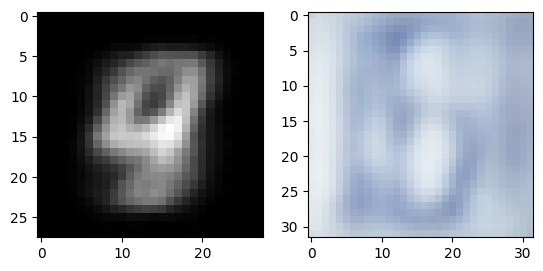

In [4]:
num_imgs = 10
gen_mnist, gen_svhn = vae.generation(num_imgs=num_imgs)
plt.subplot(1,2,1)
plt.imshow(gen_mnist[0].squeeze(), cmap="gray") # Squeeze to match dimensions

plt.subplot(1,2,2)
plt.imshow(gen_svhn[0].permute(1,2,0)) # Permuting to match dimensions
plt.show()

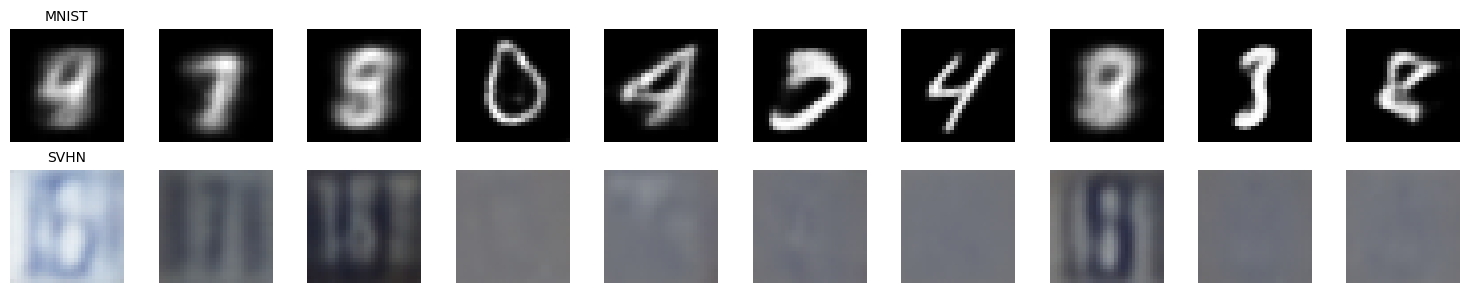

In [5]:
fig, axes = plt.subplots(2,num_imgs, figsize=(15, 3))

for i in range(num_imgs):
  # MNIST row
  axes[0, i].imshow(gen_mnist[i].squeeze(), cmap="gray")
  axes[0, i].axis("off")
  if i == 0:
    axes[0, i].set_title("MNIST", fontsize=10)

  # SVHN row
  axes[1, i].imshow(gen_svhn[i].permute(1, 2, 0))
  axes[1, i].axis("off")
  if i == 0:
    axes[1, i].set_title("SVHN", fontsize=10)

plt.tight_layout()
plt.show()

In [6]:
transform = T.ToTensor() # Converts to Torch Tensor (C, H, W) so it can be later trained on


# Downloading test data
mnist_test = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transform 
)
svhn_test = torchvision.datasets.SVHN(
    root="./data", split="test", download=True, transform=transform
)

# Same operations as in training for combining both datasets
mnist_test_indices = defaultdict(list)
svhn_test_indices = defaultdict(list)

for i, label in enumerate(mnist_test.targets):
  mnist_test_indices[int(label)].append(i)

for i, label in enumerate(svhn_test.labels):
  svhn_test_indices[label].append(i)

n_test_pairs = {
    digit: min(len(mnist_test_indices[digit]), len(svhn_test_indices[digit]))
    for digit in range(10)
}

# Building test pairs
test_pairs = []
for digit in range(10):
  m_idx = mnist_test_indices[digit].copy()
  s_idx = svhn_test_indices[digit].copy()

  random.shuffle(m_idx)
  random.shuffle(s_idx)

  n = n_test_pairs[digit]
  for m, s in zip(m_idx[:n], s_idx[:n]):
    test_pairs.append((m, s, digit))

class CombinedDataset(Dataset):
    def __init__(self, mnist, svhn, pairs):
        self.mnist = mnist
        self.svhn = svhn
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        mnist_idx, svhn_idx, label = self.pairs[idx]

        img_mnist, _ = self.mnist[mnist_idx]
        img_svhn, _ = self.svhn[svhn_idx]

        return img_mnist, img_svhn, label
    
combined_test = CombinedDataset(mnist_test, svhn_test, test_pairs)
test_dataloader = DataLoader(combined_test, batch_size=10, shuffle=True) # Taking 10 images
x1_test, x2_test, labels = next(iter(test_dataloader))

## Reconstruction

In [7]:
rec_mnist, rec_svhn = vae.reconstruction(x1_test, x2_test)

### MNIST reconstruction

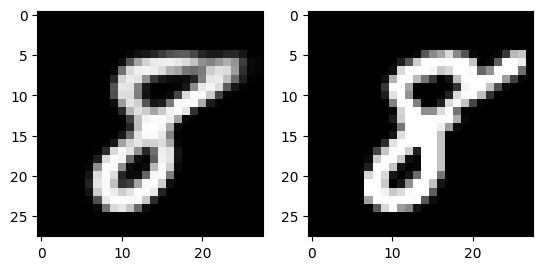

In [8]:
plt.subplot(1,2,1)
plt.imshow(rec_mnist[0].squeeze(), cmap="gray")

plt.subplot(1,2,2)
plt.imshow(x1_test[0].squeeze(), cmap="gray")

plt.show()

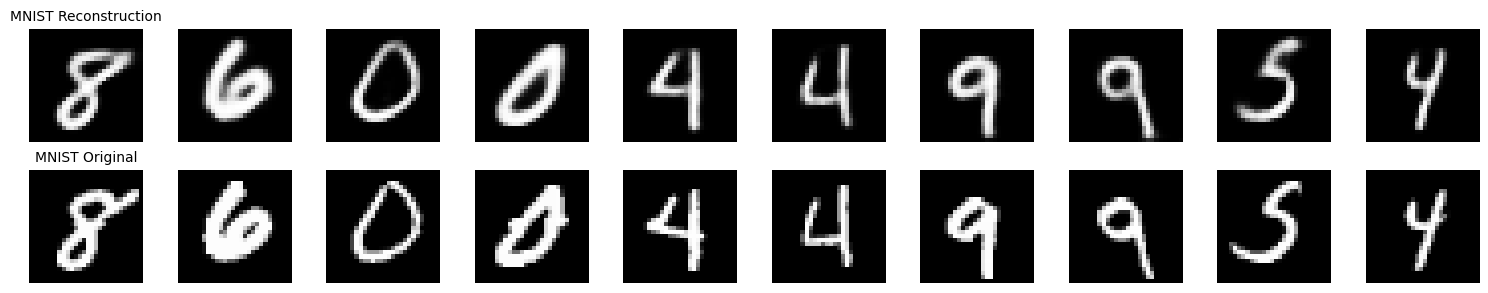

In [9]:
fig, axes = plt.subplots(2,num_imgs, figsize=(15, 3))

for i in range(num_imgs):
  axes[0, i].imshow(rec_mnist[i].squeeze(), cmap="gray")
  axes[0, i].axis("off")
  if i == 0:
    axes[0, i].set_title("MNIST Reconstruction", fontsize=10)

  axes[1, i].imshow(x1_test[i].squeeze(), cmap="gray")
  axes[1, i].axis("off")
  if i == 0:
    axes[1, i].set_title("MNIST Original", fontsize=10)

plt.tight_layout()
plt.show()

### SVHN Reconstruction

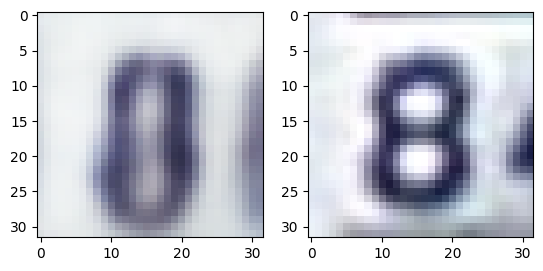

In [10]:
plt.subplot(1,2,1)
plt.imshow(rec_svhn[0].permute(1,2,0)) # Permuting to match dimensions

plt.subplot(1,2,2)
plt.imshow(x2_test[0].permute(1,2,0)) # Permuting to match dimensions
plt.show()

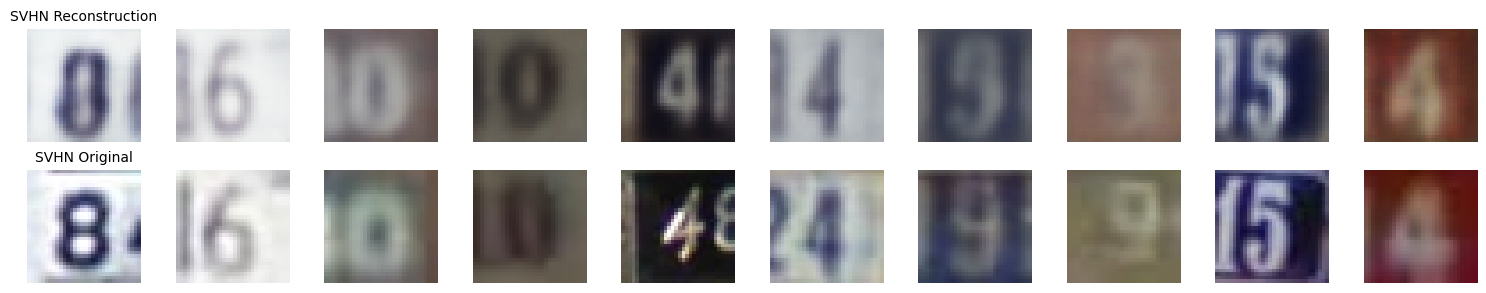

In [11]:
fig, axes = plt.subplots(2,num_imgs, figsize=(15, 3))

for i in range(num_imgs):
  axes[0, i].imshow(rec_svhn[i].permute(1,2,0))
  axes[0, i].axis("off")
  if i == 0:
    axes[0, i].set_title("SVHN Reconstruction", fontsize=10)

  axes[1, i].imshow(x2_test[i].permute(1,2,0))
  axes[1, i].axis("off")
  if i == 0:
    axes[1, i].set_title("SVHN Original", fontsize=10)

plt.tight_layout()
plt.show()

## Cross-Generation

In [12]:
mnist_from_svhn, svhn_from_mnist = vae.cross_generate(
    x1=x1_test, x2=x2_test
)

### MNIST from SVHN

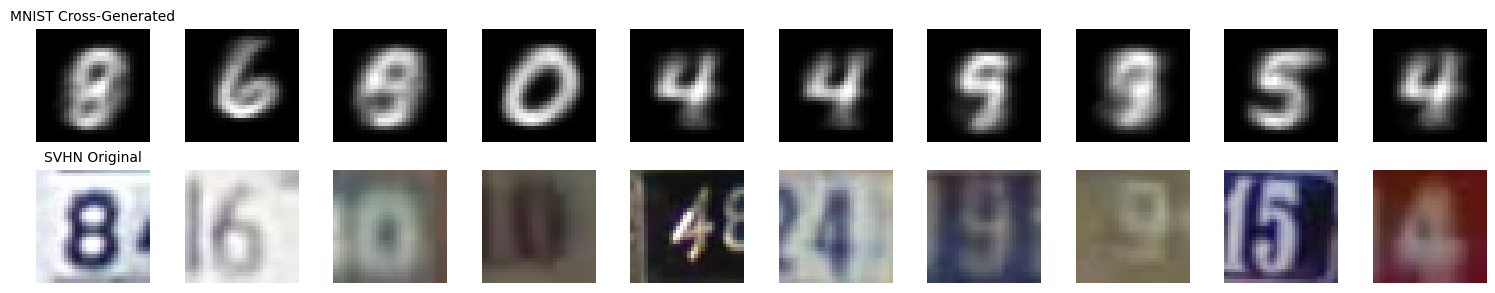

In [13]:
fig, axes = plt.subplots(2,num_imgs, figsize=(15, 3))

for i in range(num_imgs):
  axes[0, i].imshow(mnist_from_svhn[i].squeeze(), cmap="gray")
  axes[0, i].axis("off")
  if i == 0:
    axes[0, i].set_title("MNIST Cross-Generated", fontsize=10)

  axes[1, i].imshow(x2_test[i].permute(1,2,0))
  axes[1, i].axis("off")
  if i == 0:
    axes[1, i].set_title("SVHN Original", fontsize=10)

plt.tight_layout()
plt.show()

### SVHN from MNIST

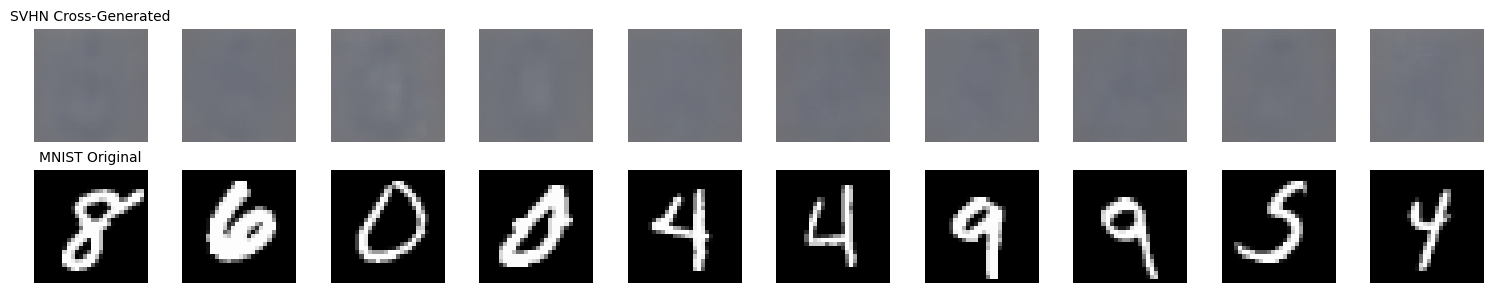

In [14]:
fig, axes = plt.subplots(2,num_imgs, figsize=(15, 3))

for i in range(num_imgs):
  axes[0, i].imshow(svhn_from_mnist[i].permute(1,2,0))
  axes[0, i].axis("off")
  if i == 0:
    axes[0, i].set_title("SVHN Cross-Generated", fontsize=10)


  axes[1, i].imshow(x1_test[i].squeeze(), cmap="gray")
  axes[1, i].axis("off")
  if i == 0:
    axes[1, i].set_title("MNIST Original", fontsize=10)

plt.tight_layout()
plt.show()

## T-SNE

c:\Users\javie\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\javie\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\javie\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\javie\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, c

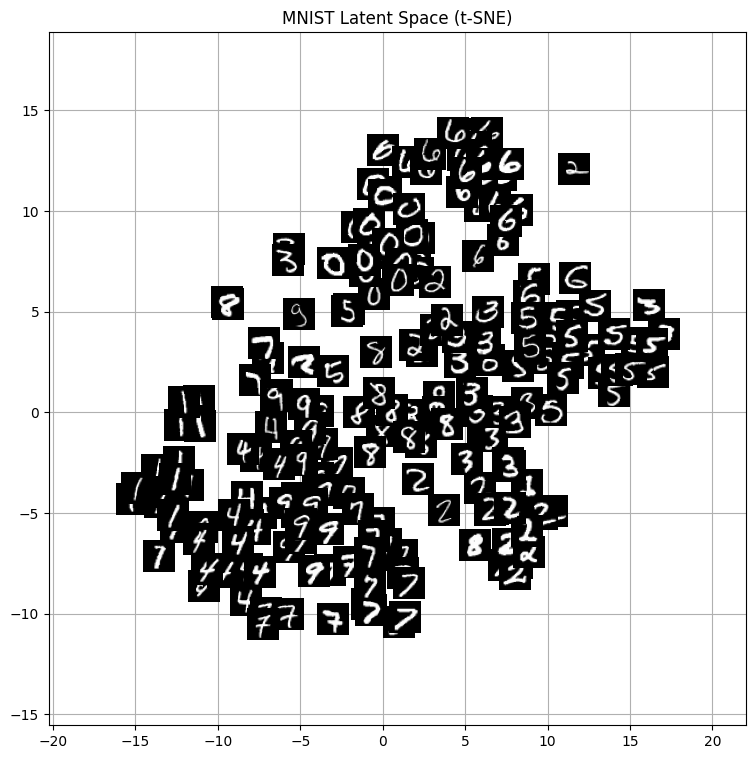

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from sklearn.manifold import TSNE
import torch
device = "cpu"

def format_img_for_plot(img_tensor, is_mnist=True):
    # Convert from PyTorch (C, H, W) to  NumPy array
    img_np = img_tensor.detach().numpy()
    
    if is_mnist:
        return img_np.squeeze()
    else:
        return np.transpose(img_np, (1, 2, 0))

def plot_latent_space_with_images(images, latent_2d, is_mnist=True, title="Latent Space Z"):
    fig, ax = plt.subplots(1, 1, figsize=(9, 9))
    
    for i in range(len(images)):
        img_formatted = format_img_for_plot(images[i], is_mnist=is_mnist)
        
        # Select colorma
        cmap = "gray" if is_mnist else None
        im = OffsetImage(img_formatted, zoom=0.8, cmap=cmap)
        
        ab = AnnotationBbox(im, latent_2d[i, :], frameon=False)
        ax.add_artist(ab)
        
    # Auto-scale plot boundaries with padding
    pad = 5
    ax.set_xlim(latent_2d[:, 0].min() - pad, latent_2d[:, 0].max() + pad)
    ax.set_ylim(latent_2d[:, 1].min() - pad, latent_2d[:, 1].max() + pad)
    ax.set_title(title)
    plt.grid(True)
    plt.show()

# Obtaining a larger batch for plotting
vae.eval()
test_dataloader_tsne = DataLoader(combined_test, batch_size=200, shuffle=True)
x1_batch, x2_batch, labels = next(iter(test_dataloader_tsne))


# Obtaining latent representation (z_batch)
with torch.no_grad():
    mu1_batch, _, _ = vae.encoder1.encode(x1_batch) # MNIST latents
    mu2_batch, _, _ = vae.encoder2.encode(x2_batch) # SVHN latents

# t-SNE on Mnist
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
latent_tsne_mnist = tsne.fit_transform(mu1_batch.numpy())

# Plot MNIST Latent Space
plot_latent_space_with_images(x1_batch, latent_tsne_mnist, is_mnist=True, title="MNIST Latent Space (t-SNE)")

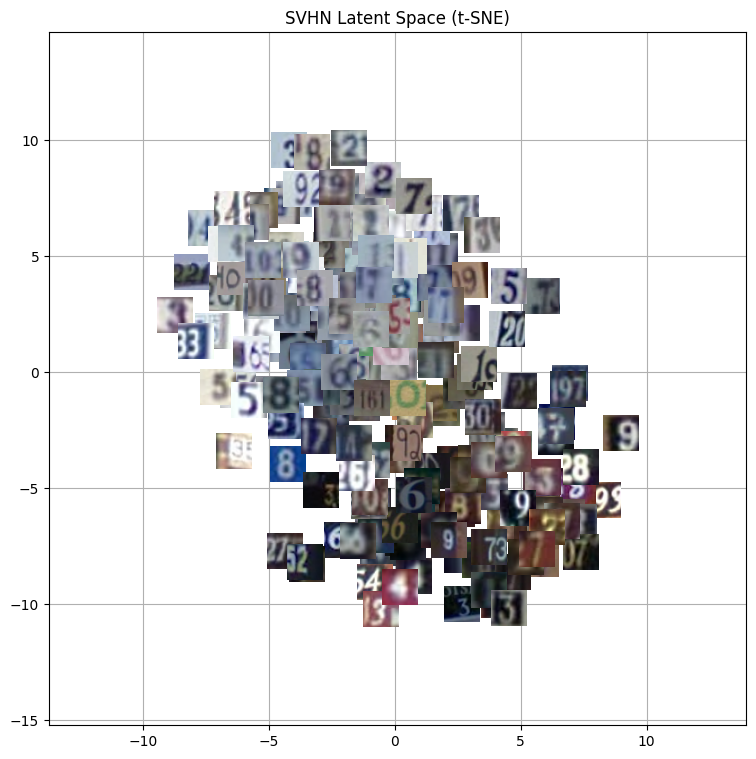

In [16]:
# t-SNE on SVHN
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
latent_tsne_svhn = tsne.fit_transform(mu2_batch.numpy())

# Plot MNIST Latent Space
plot_latent_space_with_images(x2_batch, latent_tsne_svhn, is_mnist=False, title="SVHN Latent Space (t-SNE)")